Section 1 – **Introduction**


 -- Exploratory Data Analysis of House Prices



Section 2 – **Setup and First Look**


-- Import Libraries

In [39]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")


-- Load dataset

In [40]:

df = pd.read_csv('/content/train.csv')

print("Dataset loaded successfully!")


Dataset loaded successfully!


first look

In [41]:

print("Dataset Shape:", df.shape)

display(df.head())

df.info()


Dataset Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

missingg values

In [42]:

missing = df.isnull().sum()

print(missing[missing > 0].sort_values(ascending=False))


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


Section 3 – **Classification of Variables**

In [43]:

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df.select_dtypes(include='object').columns.tolist()

ordinal_cols = ['OverallQual', 'OverallCond',
                'ExterQual', 'KitchenQual']

variable_summary = []

for col in df.columns:
    if col in ordinal_cols:
        var_type = 'Ordinal'
    elif col in numeric_cols:
        var_type = 'Numerical'
    else:
        var_type = 'Categorical'

    variable_summary.append({
        'Column Name': col,
        'Type': var_type,
        'Unique Values': df[col].nunique(),
        'Example Values': str(df[col].dropna().unique()[:3])
    })

variable_df = pd.DataFrame(variable_summary)

display(variable_df)


,Column Name,Type,Unique Values,Example Values
0,Id,Numerical,1460,[1 2 3]
1,MSSubClass,Numerical,15,[60 20 70]
2,MSZoning,Categorical,5,['RL' 'RM' 'C (all)']
3,LotFrontage,Numerical,110,[65. 80. 68.]
4,LotArea,Numerical,1073,[ 8450 9600 11250]
...,...,...,...,...
76,MoSold,Numerical,12,[2 5 9]
77,YrSold,Numerical,5,[2008 2007 2006]
78,SaleType,Categorical,9,['WD' 'New' 'COD']
79,SaleCondition,Categorical,6,['Normal' 'Abnorml' 'Partial']


Sec-4 **Descriptive Statistics**

-- Basic statictics

In [44]:

df.describe()


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


-- Detailed statistical analysis

In [45]:

columns = ['SalePrice', 'GrLivArea', 'LotArea']

for col in columns:
    print("\nColumn:", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])
    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())
    print("Range:", df[col].max() - df[col].min())
    print("IQR:", df[col].quantile(0.75) - df[col].quantile(0.25))
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())



Column: SalePrice
Mean: 180921.19589041095
Median: 163000.0
Mode: 140000
Standard Deviation: 79442.50288288663
Variance: 6311111264.297451
Range: 720100
IQR: 84025.0
Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529

Column: GrLivArea
Mean: 1515.463698630137
Median: 1464.0
Mode: 864
Standard Deviation: 525.4803834232027
Variance: 276129.63336259616
Range: 5308
IQR: 647.25
Skewness: 1.3665603560164552
Kurtosis: 4.895120580693174

Column: LotArea
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200
Standard Deviation: 9981.264932379147
Variance: 99625649.6503417
Range: 213945
IQR: 4048.0
Skewness: 12.207687851233496
Kurtosis: 203.24327101886033


-- Categorical statistics

In [46]:

print("Neighborhood Frequency:")
display(df['Neighborhood'].value_counts())

print("House Style Frequency:")
display(df['HouseStyle'].value_counts())


Neighborhood Frequency:


,count
Neighborhood,
NAmes,225
CollgCr,150
OldTown,113
Edwards,100
Somerst,86
Gilbert,79
NridgHt,77
Sawyer,74
NWAmes,73


House Style Frequency:


,count
HouseStyle,
1Story,726
2Story,445
1.5Fin,154
SLvl,65
SFoyer,37
1.5Unf,14
2.5Unf,11
2.5Fin,8


Section 5 – **Distribution Analysis**

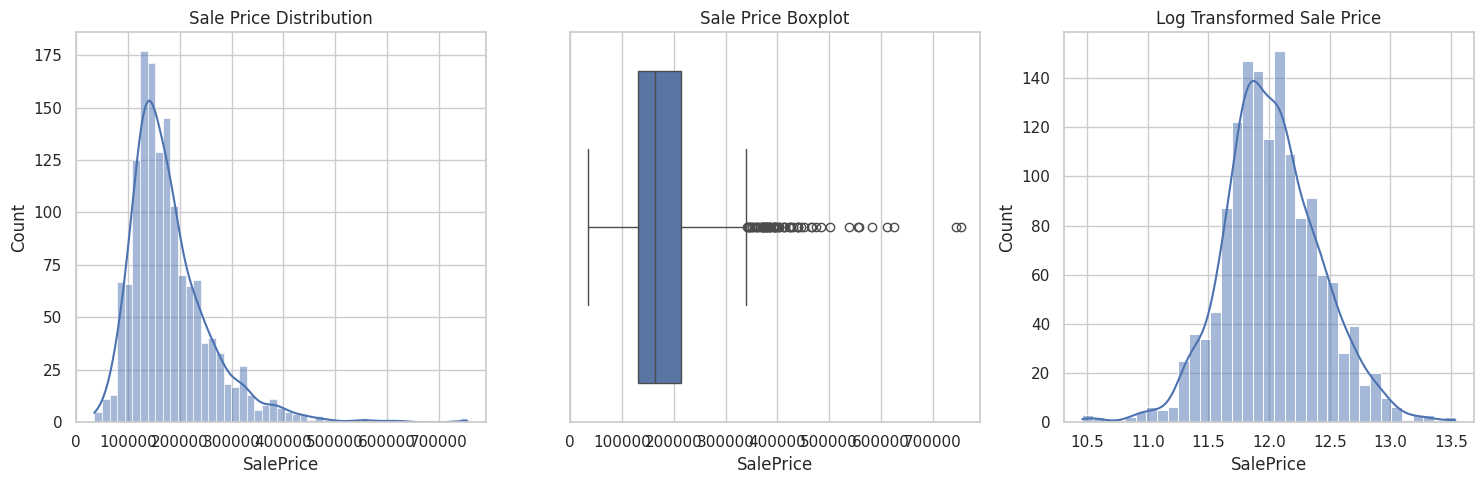

In [47]:

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.histplot(df['SalePrice'], kde=True)
plt.title('Sale Price Distribution')

plt.subplot(1, 3, 2)
sns.boxplot(x=df['SalePrice'])
plt.title('Sale Price Boxplot')

plt.subplot(1, 3, 3)
sns.histplot(np.log1p(df['SalePrice']), kde=True)
plt.title('Log Transformed Sale Price')

plt.tight_layout()
plt.show()


-- xHouse Quality vs Price

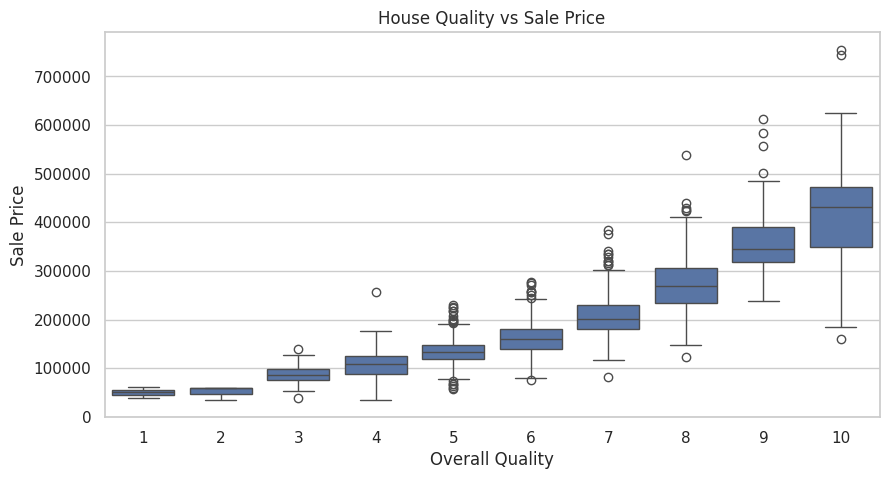

In [48]:

plt.figure(figsize=(10, 5))

sns.boxplot(x='OverallQual', y='SalePrice', data=df)

plt.title('House Quality vs Sale Price')
plt.xlabel('Overall Quality')
plt.ylabel('Sale Price')

plt.show()


-- Neighborhood vs Price

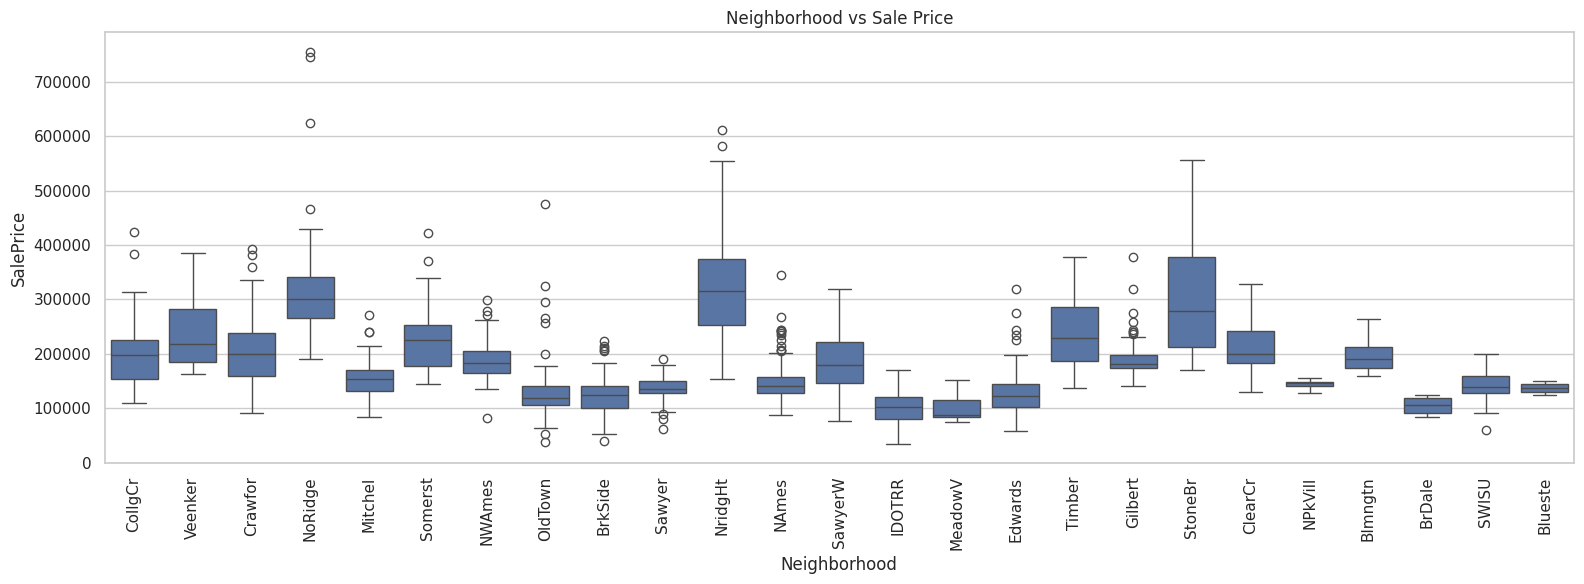

In [49]:

plt.figure(figsize=(16, 6))

sns.boxplot(x='Neighborhood', y='SalePrice', data=df)

plt.title('Neighborhood vs Sale Price')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()


-- Countplots

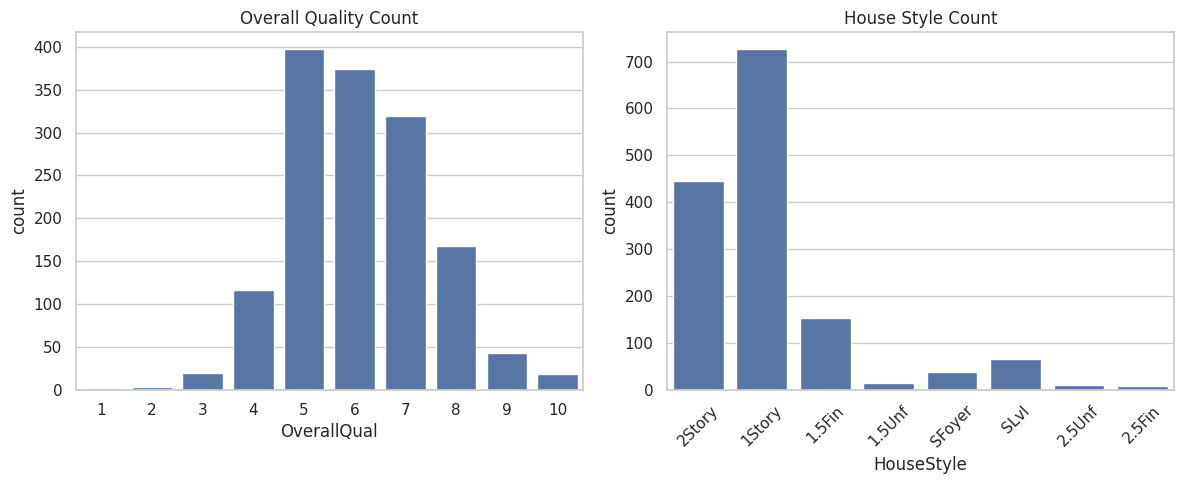

In [50]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.countplot(x='OverallQual', data=df)
plt.title('Overall Quality Count')

plt.subplot(1, 2, 2)
sns.countplot(x='HouseStyle', data=df)
plt.title('House Style Count')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


Section 6 – **Correlation and Covariance**

-- Correlation and Covariance

In [51]:

numeric_df = df.select_dtypes(include=np.number)

corr_matrix = numeric_df.corr()
cov_matrix = numeric_df.cov()

print("Top 10 Features Correlated with SalePrice:")

top_corr = corr_matrix['SalePrice'].drop('SalePrice').abs().sort_values(ascending=False)

display(top_corr.head(10))


Top 10 Features Correlated with SalePrice:


,SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


-- Compare top 3 features

In [52]:

top_3 = top_corr.head(3).index

for col in top_3:
    print("\nFeature:", col)
    print("Correlation:", corr_matrix.loc[col, 'SalePrice'])
    print("Covariance:", cov_matrix.loc[col, 'SalePrice'])



Feature: OverallQual
Correlation: 0.7909816005838053
Covariance: 86904.12583679946

Feature: GrLivArea
Correlation: 0.7086244776126515
Covariance: 29581866.743236575

Feature: GarageCars
Correlation: 0.6404091972583519
Covariance: 38020.18135897172


-- Spearman correlation

In [53]:

ordinal_data = df[['OverallQual', 'OverallCond', 'SalePrice']]

display(ordinal_data.corr(method='spearman'))


,OverallQual,OverallCond,SalePrice
OverallQual,1.000000,-0.177521,0.809829
OverallCond,-0.177521,1.000000,-0.129325
SalePrice,0.809829,-0.129325,1.000000


Section 7 – **Scatter Plots and Pair Plots**

--Living Area vs Sale Price

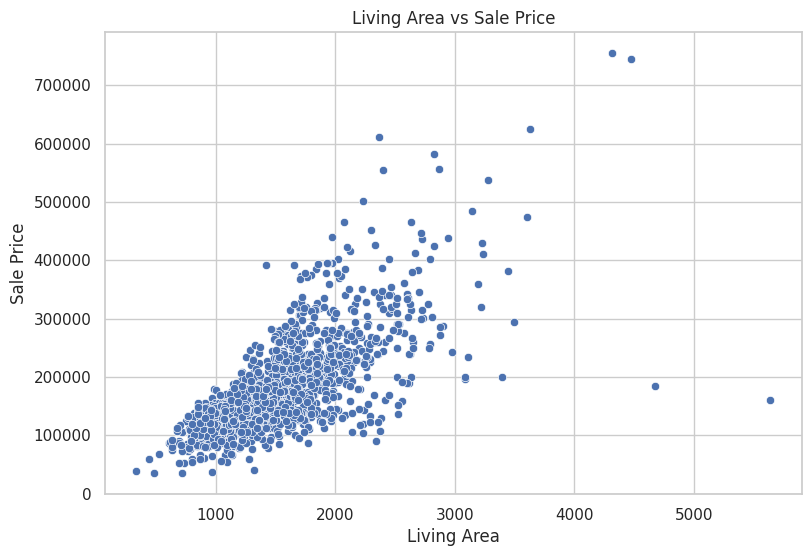

In [54]:

plt.figure(figsize=(9, 6))

sns.scatterplot(x='GrLivArea', y='SalePrice', data=df)

plt.title('Living Area vs Sale Price')
plt.xlabel('Living Area')
plt.ylabel('Sale Price')

plt.show()


--Basement Area vs Sale Price

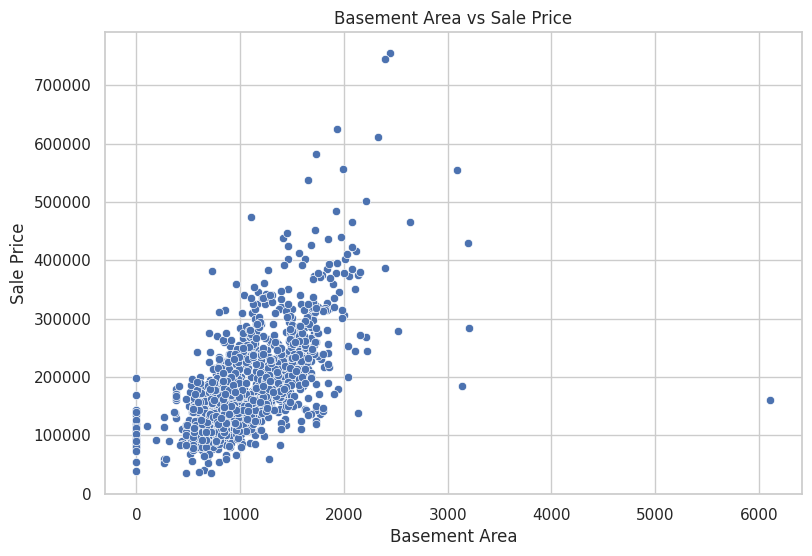

In [55]:

plt.figure(figsize=(9, 6))

sns.scatterplot(x='TotalBsmtSF', y='SalePrice', data=df)

plt.title('Basement Area vs Sale Price')
plt.xlabel('Basement Area')
plt.ylabel('Sale Price')

plt.show()


--Year Built vs Sale Price

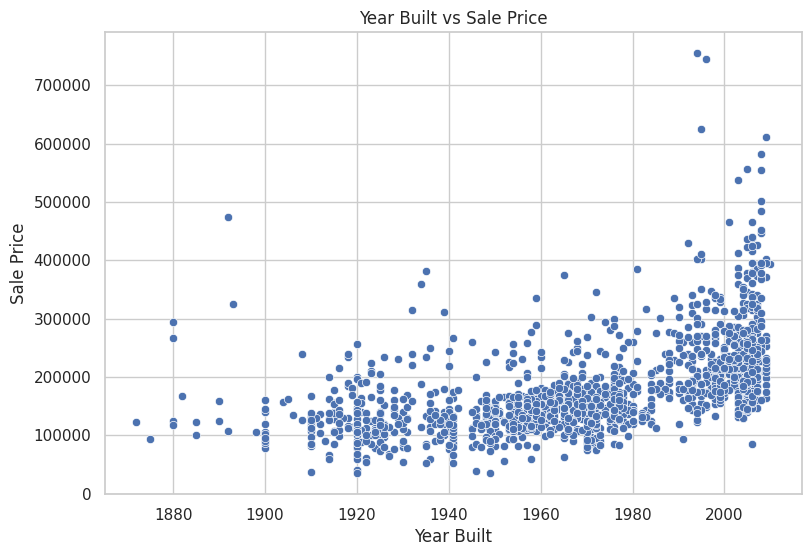

In [56]:

plt.figure(figsize=(9, 6))

sns.scatterplot(x='YearBuilt', y='SalePrice', data=df)

plt.title('Year Built vs Sale Price')
plt.xlabel('Year Built')
plt.ylabel('Sale Price')

plt.show()


--Pair Plot

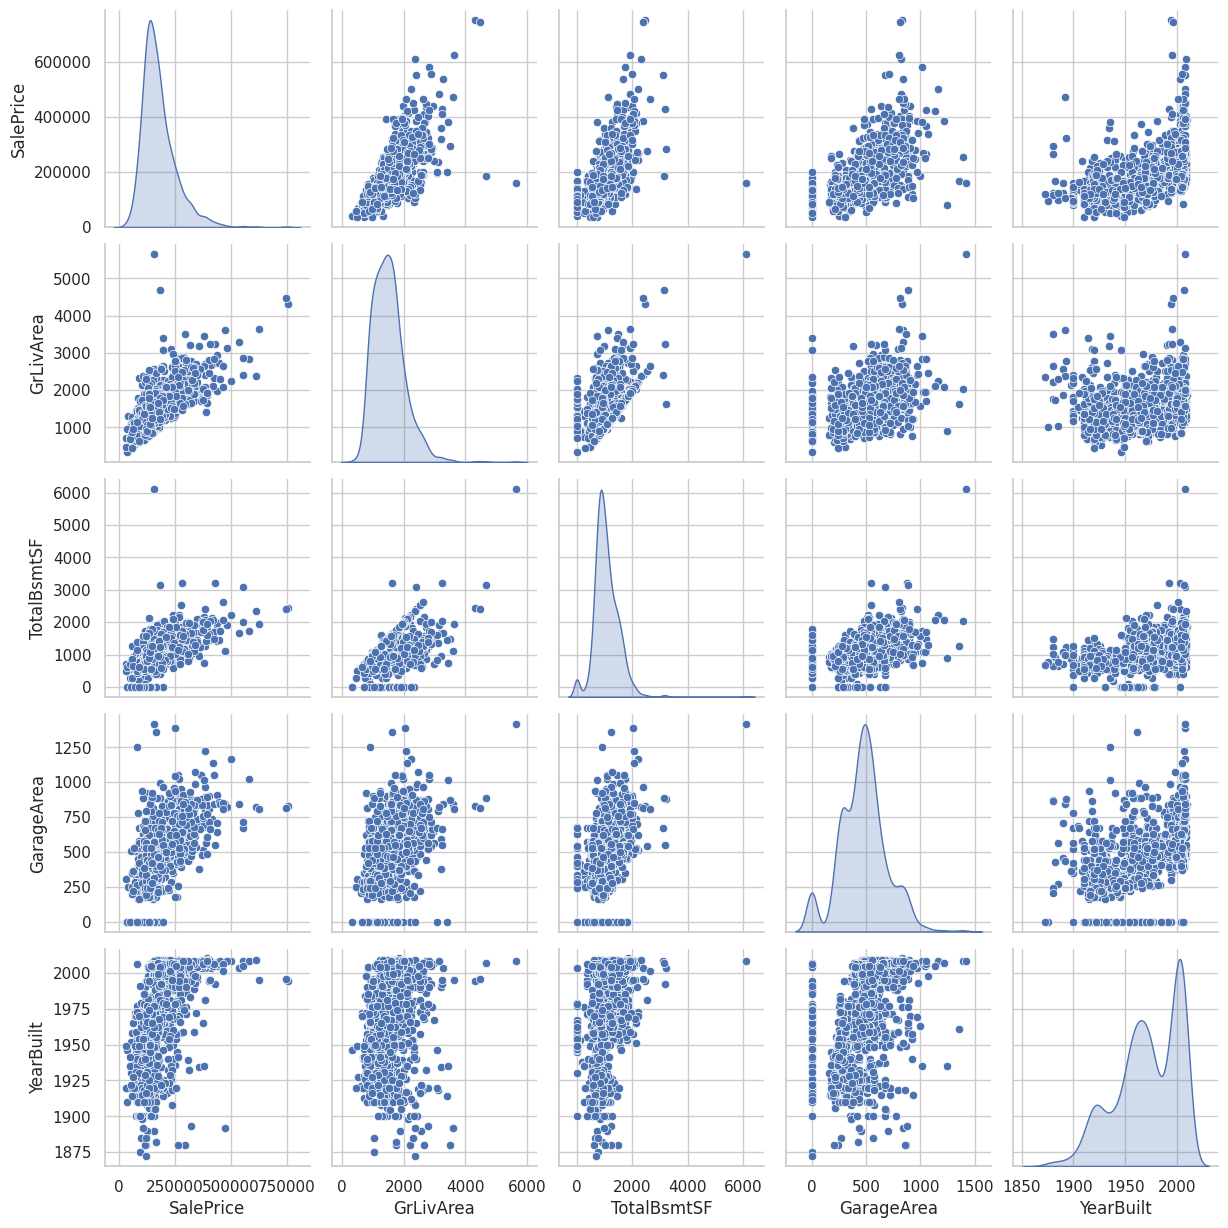

In [57]:

selected = ['SalePrice', 'GrLivArea', 'TotalBsmtSF',
            'GarageArea', 'YearBuilt']

sns.pairplot(df[selected], diag_kind='kde')

plt.show()


Section 8 – **Correlation Heatmap**

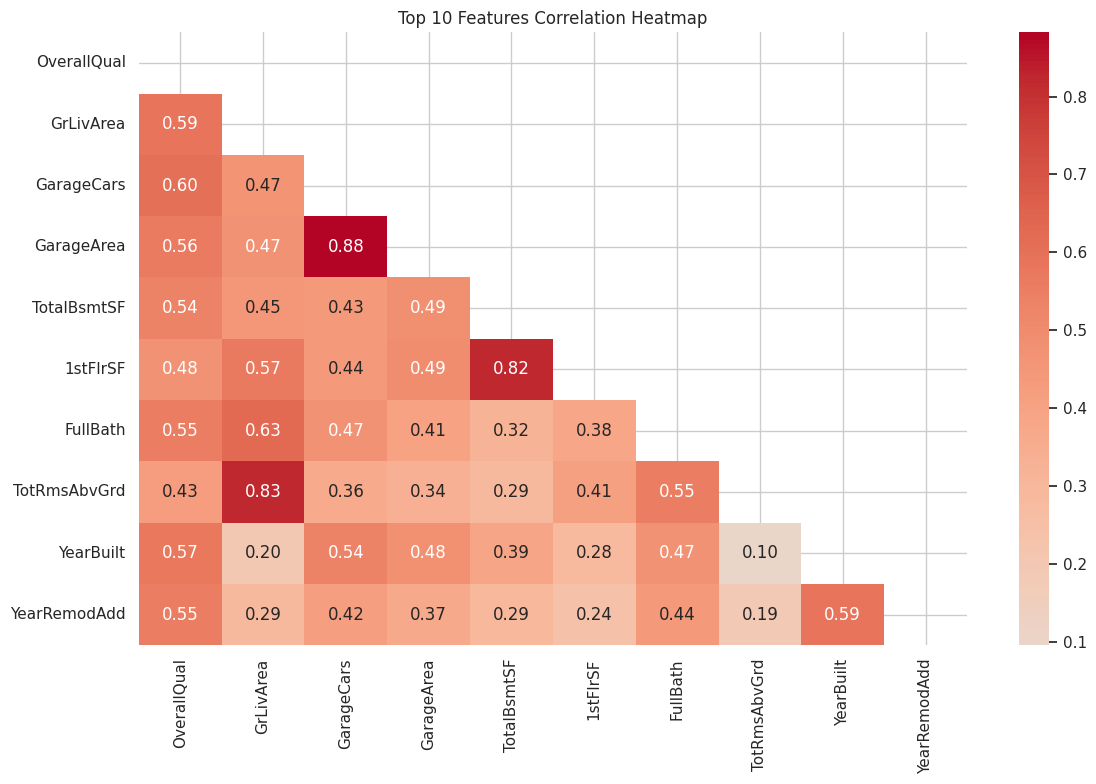

In [58]:

top10_features = top_corr.head(10).index.tolist()

corr_top = df[top10_features].corr()

plt.figure(figsize=(12, 8))

mask = np.triu(np.ones_like(corr_top, dtype=bool))

sns.heatmap(
    corr_top,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    mask=mask
)

plt.title('Top 10 Features Correlation Heatmap')
plt.tight_layout()
plt.show()


Section 9 – **Outlier Detection**

--IQR and Z-score methods

In [59]:

def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return series[(series < lower) | (series > upper)]


def zscore_outliers(series):
    z = stats.zscore(series.dropna())
    return series.dropna()[np.abs(z) > 3]


for col in ['GrLivArea', 'SalePrice']:
    iqr_result = iqr_outliers(df[col])
    z_result = zscore_outliers(df[col])

    print("\nColumn:", col)
    print("IQR Outliers:", len(iqr_result))
    print("Z-score Outliers:", len(z_result))
    print("Overlap:", len(set(iqr_result.index) & set(z_result.index)))



Column: GrLivArea
IQR Outliers: 31
Z-score Outliers: 16
Overlap: 16

Column: SalePrice
IQR Outliers: 61
Z-score Outliers: 22
Overlap: 22


--Visualise outliers

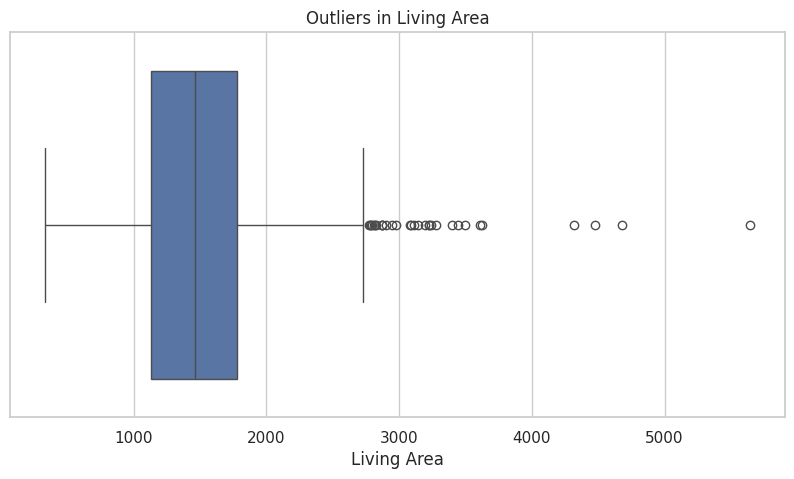

In [60]:

plt.figure(figsize=(10, 5))

sns.boxplot(x=df['GrLivArea'])

plt.title('Outliers in Living Area')
plt.xlabel('Living Area')

plt.show()


--Scatter plot highlighting unusual houses

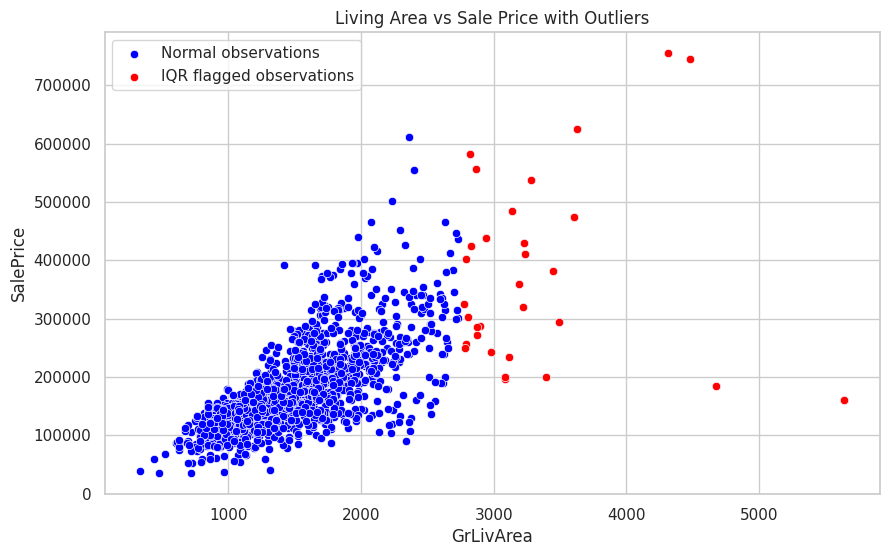

In [61]:

outlier_indices = iqr_outliers(df['GrLivArea']).index

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='GrLivArea', y='SalePrice',
                color='blue', label='Normal observations')

sns.scatterplot(data=df.loc[outlier_indices],
                x='GrLivArea', y='SalePrice',
                color='red', label='IQR flagged observations')

plt.title('Living Area vs Sale Price with Outliers')
plt.legend()
plt.show()


Section 10 – **Data Quality Checks**

--Check duplicates

In [62]:

print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)


Duplicate Rows: 0
Dataset Shape After Removing Duplicates: (1460, 81)


--Handle missing values

In [63]:

# Fill missing values where NA means the feature is absent

absence_cols = [
    'PoolQC', 'Alley', 'Fence',
    'FireplaceQu', 'GarageType'
]

for col in absence_cols:
    if col in df.columns:
        df[col] = df[col].fillna('None')


# Fill remaining categorical missing values
categorical_missing = df.select_dtypes(include='object').columns

for col in categorical_missing:
    df[col] = df[col].fillna(df[col].mode()[0])


# Fill numerical missing values with median
numerical_missing = df.select_dtypes(include=np.number).columns

for col in numerical_missing:
    df[col] = df[col].fillna(df[col].median())


print("Remaining Missing Values:", df.isnull().sum().sum())


Remaining Missing Values: 0


--Check impossible values

In [64]:

print("Houses built after sale year:",
      (df['YearBuilt'] > df['YrSold']).sum())

print("Negative living areas:",
      (df['GrLivArea'] < 0).sum())

print("Negative lot areas:",
      (df['LotArea'] < 0).sum())

print("Final Dataset Shape:", df.shape)


Houses built after sale year: 0
Negative living areas: 0
Negative lot areas: 0
Final Dataset Shape: (1460, 81)


Section 11 – **Final Dashboard**

--Create the dashboard

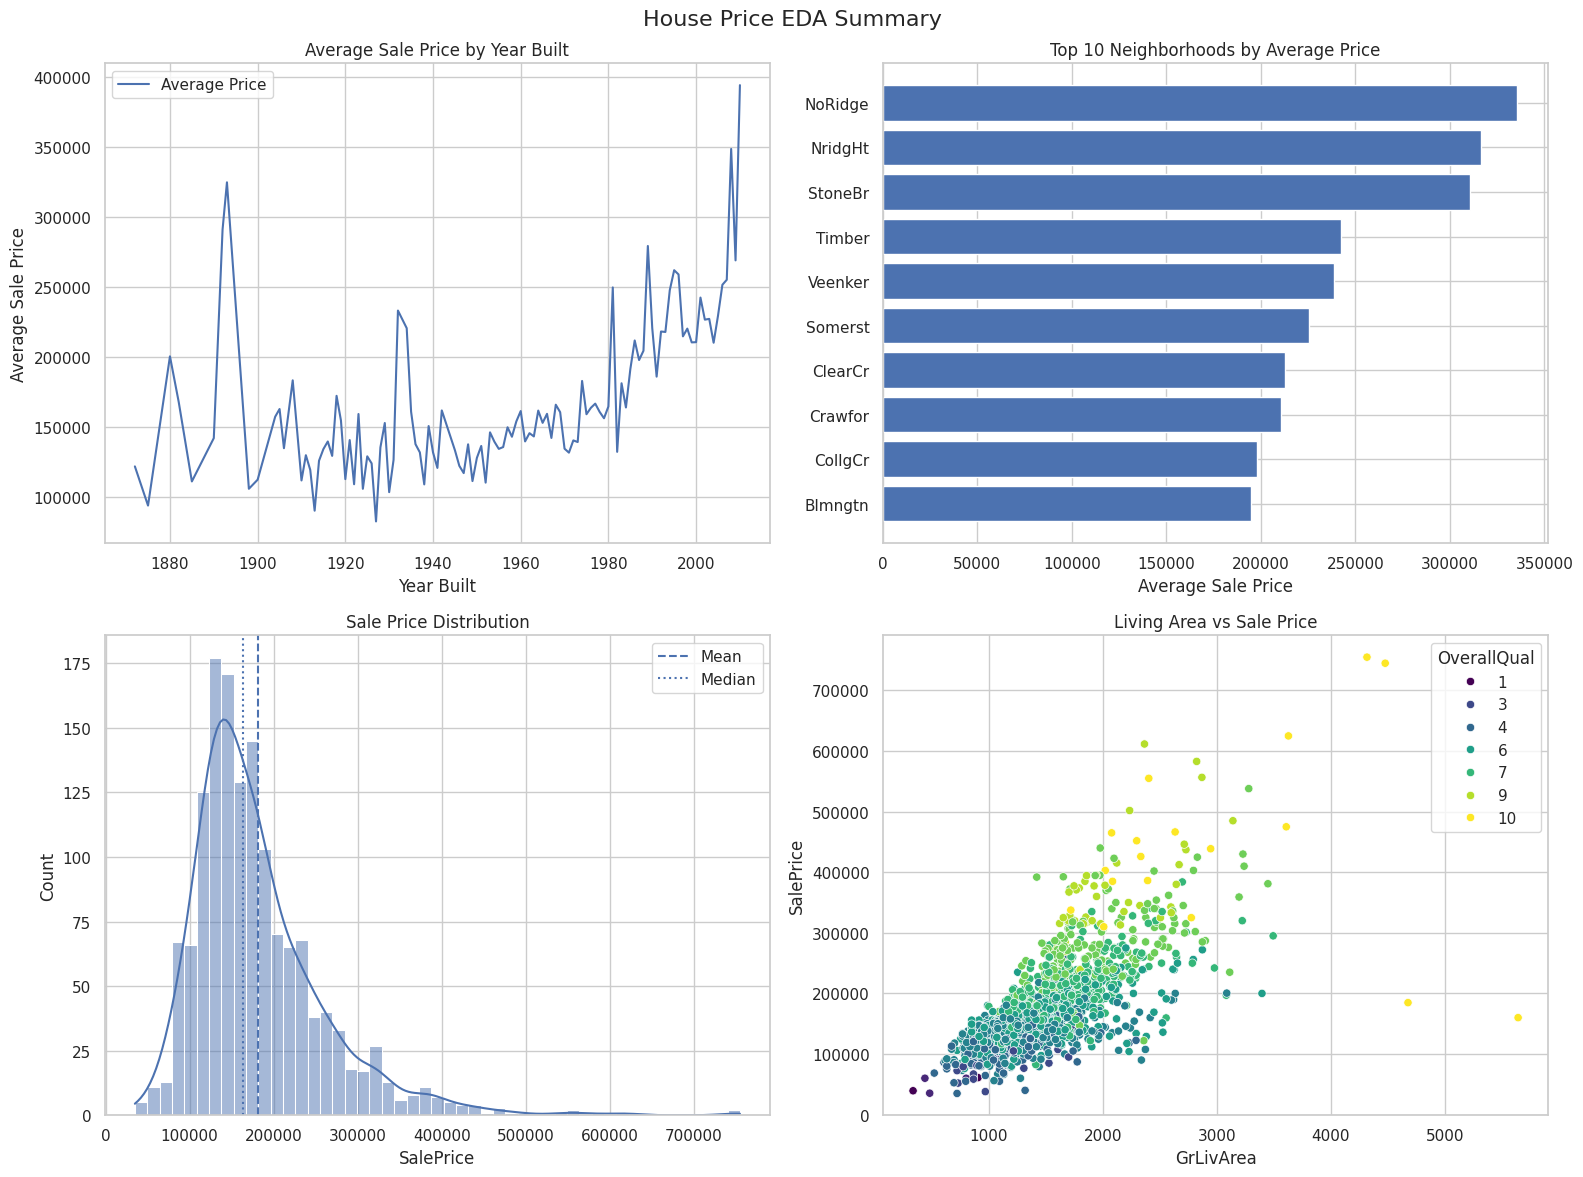

Dashboard saved successfully!


In [65]:

fig, axes = plt.subplots(2, 2, figsize=(16, 12))


yearly_price = df.groupby('YearBuilt')['SalePrice'].mean()

axes[0, 0].plot(yearly_price.index, yearly_price.values,
                label='Average Price')

axes[0, 0].set_title('Average Sale Price by Year Built')
axes[0, 0].set_xlabel('Year Built')
axes[0, 0].set_ylabel('Average Sale Price')
axes[0, 0].legend()



top_neighborhoods = (
    df.groupby('Neighborhood')['SalePrice']
    .mean().sort_values(ascending=False).head(10)
)

axes[0, 1].barh(top_neighborhoods.index,
                top_neighborhoods.values)

axes[0, 1].set_title('Top 10 Neighborhoods by Average Price')
axes[0, 1].set_xlabel('Average Sale Price')
axes[0, 1].invert_yaxis()



sns.histplot(df['SalePrice'], kde=True, ax=axes[1, 0])

axes[1, 0].axvline(df['SalePrice'].mean(),
                   linestyle='--', label='Mean')

axes[1, 0].axvline(df['SalePrice'].median(),
                   linestyle=':', label='Median')

axes[1, 0].set_title('Sale Price Distribution')
axes[1, 0].legend()



sns.scatterplot(
    data=df,
    x='GrLivArea',
    y='SalePrice',
    hue='OverallQual',
    ax=axes[1, 1],
    palette='viridis'
)

axes[1, 1].set_title('Living Area vs Sale Price')



plt.suptitle('House Price EDA Summary', fontsize=16)

plt.tight_layout()

plt.savefig('eda_dashboard.png', dpi=300, bbox_inches='tight')

plt.show()

print("Dashboard saved successfully!")


Section 12 – **Conclusion**


The Exploratory Data Analysis helped us understand the Ames Housing Dataset and the factors related to house prices.

From the analysis, we observed that:

- House quality and living area are strongly related to sale prices.
- House prices vary across different neighbourhoods.
- The sale price distribution is right-skewed.
- Some houses have unusually large areas or prices.
- The dataset contains missing values that need proper handling.
- Graphs and statistical methods helped us understand the relationships between different features.

Overall, this project helped us explore real-world housing data using Python, perform statistical analysis and present the findings through visualisations.
